# Vision — Clustering Gambar (tanpa label)
**Kapan dipakai:** ada tumpukan gambar tanpa label dan soal meminta "kelompokkan" / "temukan
tema" / "berapa jenis gambar yang ada". Ingin sekalian melabeli? Pakai `anotasi_klasifikasi`.

**Bentuk data yang didukung:** semua gambar di satu folder, termasuk subfoldernya (aktif), atau
daftar nama file di CSV (sel alternatif).

**Langkah:** embedding CLIP → UMAP (peta ringkas) → KMeans (jumlah klaster ditentukan) atau
HDBSCAN (jumlah klaster otomatis, titik aneh = -1) → lihat contoh gambar tiap klaster.
Alternatif reduksi: PCA (baris `#`). Skor: NMI/ARI terhadap label demo (jika ada label).

**Data demo:** gambar `pets/train` (10 ras kucing/anjing, ada GIF/grayscale/RGBA). Label di
`train.csv` hanya dipakai di sel terakhir untuk mengukur, bukan untuk melatih.

In [1]:
import glob
import os

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import umap
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from transformers import CLIPModel, CLIPProcessor

Z:\GEMASTIK\Vignate-GEMASTIK\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/pets"    # GANTI saat lomba
IMAGE_FOLDER = f"{DATA_FOLDER}/train"             # semua subfolder ikut dicari
KEY_CSV = f"{DATA_FOLDER}/train.csv"              # HANYA DEMO: label asli untuk mengukur
CLIP_FOLDER = "../../pretrained/clip_b32"
OUTPUT_FOLDER = "../../outputs/vision/clustering"   # di luar repo
os.makedirs(OUTPUT_FOLDER, exist_ok=True)

N_CLUSTERS = 10         # untuk KMeans. Tidak tahu? lihat silhouette di bawah
MIN_CLUSTER_SIZE = 15   # HDBSCAN: klaster paling kecil yang dianggap sah
EXAMPLES_PER_CLUSTER = 8
BATCH_SIZE = 64
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data — semua gambar di folder (aktif)
`**` + `recursive=True` = cari juga di dalam subfolder. Saring ekstensi gambar yang umum.

In [3]:
image_paths = []
for path in sorted(glob.glob(f"{IMAGE_FOLDER}/**/*", recursive=True)):
    if path.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp")):
        image_paths.append(path.replace("\\", "/"))
image_ids = []
for path in image_paths:
    image_ids.append(os.path.relpath(path, IMAGE_FOLDER).replace("\\", "/"))
print("jumlah gambar:", len(image_paths), "| contoh:", image_ids[0])

jumlah gambar: 805 | contoh: Abyssinian_1.jpg


## (Alternatif) daftar nama file di CSV

In [4]:
# images = pd.read_csv(f"{DATA_FOLDER}/images.csv")
# image_ids = list(images["id"].astype(str))
# image_paths = []
# for image_id in image_ids:
#     image_paths.append(f"{IMAGE_FOLDER}/{image_id}")

## Embedding CLIP (beku)
`convert("RGB")` menyamakan GIF/grayscale/RGBA. Vektor dibuat panjang 1 (cosine).

In [5]:
clip = CLIPModel.from_pretrained(CLIP_FOLDER, local_files_only=True)
clip = clip.to(DEVICE)
clip.eval()
processor = CLIPProcessor.from_pretrained(CLIP_FOLDER, local_files_only=True)

batches = []
for start in range(0, len(image_paths), BATCH_SIZE):
    batch_images = []
    for path in image_paths[start:start + BATCH_SIZE]:
        batch_images.append(Image.open(path).convert("RGB"))
    encoded = processor(images=batch_images, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        output = clip.get_image_features(**encoded)
    batches.append(output.pooler_output.cpu().numpy())
embedding = np.concatenate(batches)
embedding = embedding / np.linalg.norm(embedding, axis=1, keepdims=True)   # panjang 1
print(embedding.shape)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 23185.50it/s]

(805, 512)


## Reduksi dimensi: UMAP
Klaster dicari di ruang 10 dimensi, peta 2D hanya untuk digambar.
Pilih SATU blok: UMAP (aktif) atau PCA (lebih cepat, hasil biasanya lebih kasar).

In [6]:
umap_10d = umap.UMAP(n_components=10, n_neighbors=15, min_dist=0.0, metric="cosine",
                     random_state=SEED)
X_10d = umap_10d.fit_transform(embedding)
umap_2d = umap.UMAP(n_components=2, n_neighbors=15, metric="cosine", random_state=SEED)
X_2d = umap_2d.fit_transform(embedding)

# X_10d = PCA(n_components=10, random_state=SEED).fit_transform(embedding)
# X_2d = PCA(n_components=2, random_state=SEED).fit_transform(embedding)

Z:\GEMASTIK\Vignate-GEMASTIK\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Z:\GEMASTIK\Vignate-GEMASTIK\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


## Berapa klaster? Silhouette untuk beberapa jumlah
Silhouette makin dekat 1 makin rapi (tanpa label). Pilih jumlah dengan nilai tinggi, lalu
isi `N_CLUSTERS` di Konfigurasi. Silhouette hanya petunjuk: kelas yang mirip (ras kucing
belang) sering bergabung, jadi jumlah terbaiknya bisa lebih kecil dari jumlah kelas asli.

In [7]:
for n_clusters in [4, 6, 8, 10, 12, 15]:
    trial = KMeans(n_clusters=n_clusters, n_init=5, random_state=SEED)
    trial_clusters = trial.fit_predict(X_10d)
    print(n_clusters, "klaster -> silhouette", round(silhouette_score(X_10d, trial_clusters), 3))

4 klaster -> silhouette 0.851
6 klaster -> silhouette 0.696
8 klaster -> silhouette 0.632


10 klaster -> silhouette 0.613
12 klaster -> silhouette 0.567
15 klaster -> silhouette 0.537


## Klaster: KMeans dan HDBSCAN

In [8]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
kmeans_clusters = kmeans.fit_predict(X_10d)
print("silhouette KMeans:", round(silhouette_score(X_10d, kmeans_clusters), 3))

finder = hdbscan.HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE)
hdbscan_clusters = finder.fit_predict(X_10d)      # -1 = tidak masuk klaster mana pun
n_hdbscan = len(set(hdbscan_clusters)) - 1
print("klaster HDBSCAN:", n_hdbscan, "| titik -1:", (hdbscan_clusters == -1).sum())

silhouette KMeans: 0.613
klaster HDBSCAN: 5 | titik -1: 0


## Peta 2D

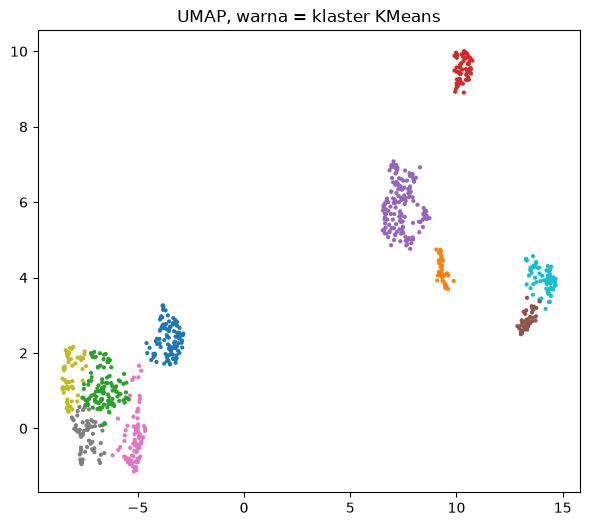

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=kmeans_clusters, cmap="tab10", s=4)
plt.title("UMAP, warna = klaster KMeans")
plt.savefig(f"{OUTPUT_FOLDER}/peta_umap.png", dpi=120)
plt.show()

## Contoh gambar tiap klaster
Gambar paling dekat ke pusat klaster = paling mewakili. Lihat contohnya, lalu beri nama
klaster itu sendiri.

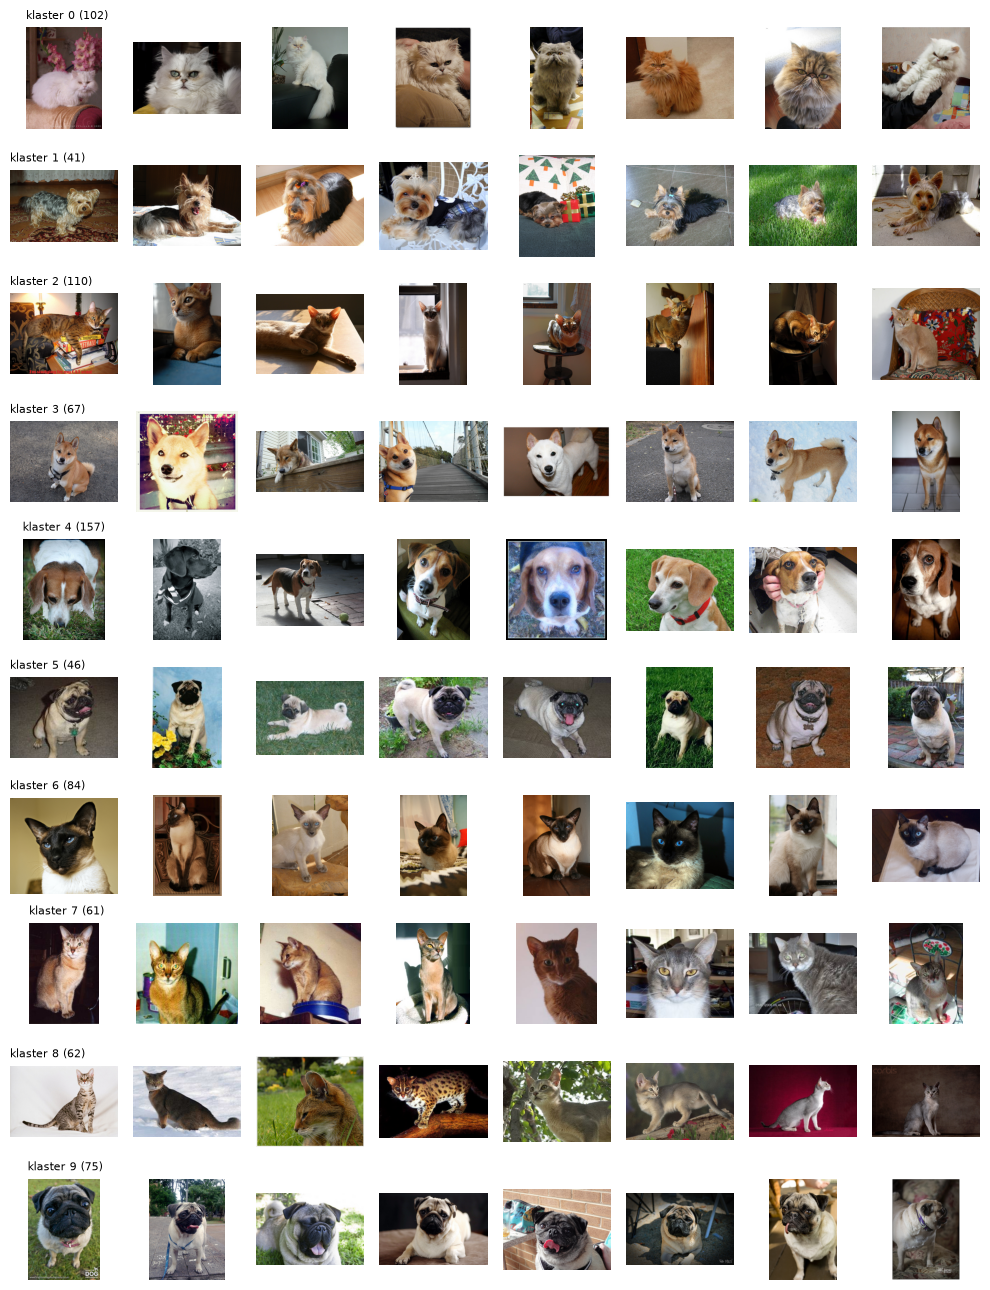

In [10]:
fig, axes = plt.subplots(N_CLUSTERS, EXAMPLES_PER_CLUSTER, figsize=(10, 1.3 * N_CLUSTERS))
for cluster in range(N_CLUSTERS):
    members = np.where(kmeans_clusters == cluster)[0]
    distances = np.linalg.norm(X_10d[members] - kmeans.cluster_centers_[cluster], axis=1)
    chosen = members[np.argsort(distances)[:EXAMPLES_PER_CLUSTER]]
    for column in range(EXAMPLES_PER_CLUSTER):
        axes[cluster, column].axis("off")
        if column < len(chosen):
            image = Image.open(image_paths[chosen[column]]).convert("RGB")
            axes[cluster, column].imshow(image)
    title = "klaster " + str(cluster) + " (" + str(len(members)) + ")"
    axes[cluster, 0].set_title(title, fontsize=8, loc="left")
plt.tight_layout()
plt.savefig(f"{OUTPUT_FOLDER}/contoh_per_klaster.png", dpi=100)
plt.show()

## Hasil
Tabel klaster per gambar (nama kolom diganti sesuai format soal).

In [11]:
result = pd.DataFrame()
result["id"] = image_ids
result["klaster_kmeans"] = kmeans_clusters
result["klaster_hdbscan"] = hdbscan_clusters
result.to_csv(f"{OUTPUT_FOLDER}/klaster.csv", index=False)
result.head()

,id,klaster_kmeans,klaster_hdbscan
0,Abyssinian_1.jpg,8,1
1,Abyssinian_100.jpg,2,1
2,Abyssinian_101.jpg,8,1
3,Abyssinian_102.jpg,2,1
4,Abyssinian_103.jpg,2,1


## Skor terhadap label demo (HAPUS saat lomba bila tidak ada label)
NMI/ARI: 1 = klaster sama persis dengan kelas asli, 0 = acak.

In [12]:
key = pd.read_csv(KEY_CSV)
true_label = dict(zip(key["id"], key["label"]))
true_labels = []
for image_id in image_ids:
    true_labels.append(true_label[image_id])
print("KMeans  NMI:", round(normalized_mutual_info_score(true_labels, kmeans_clusters), 3),
      "ARI:", round(adjusted_rand_score(true_labels, kmeans_clusters), 3))
print("HDBSCAN NMI:", round(normalized_mutual_info_score(true_labels, hdbscan_clusters), 3),
      "ARI:", round(adjusted_rand_score(true_labels, hdbscan_clusters), 3))
pd.crosstab(pd.Series(true_labels, name="asli"), pd.Series(kmeans_clusters, name="klaster"))

KMeans  NMI: 0.786 ARI: 0.679
HDBSCAN NMI: 0.825 ARI: 0.617


klaster,0,1,2,3,4,5,6,7,8,9
asli,,,,,,,,,,
Abyssinian,0,0,71,0,0,0,6,39,33,0
Bengal,0,0,31,0,0,0,0,12,10,0
Egyptian_Mau,1,0,5,0,0,0,2,4,18,0
Persian,101,0,0,0,0,0,1,3,0,0
Siamese,0,0,3,0,0,0,75,3,1,0
beagle,0,0,0,1,134,0,0,0,0,0
pug,0,0,0,0,0,46,0,0,0,74
shiba_inu,0,0,0,66,1,0,0,0,0,0
staffordshire_bull_terrier,0,0,0,0,22,0,0,0,0,1


## Masalah umum
- **Satu klaster berisi beberapa kelas mirip:** wajar untuk embedding umum. Naikkan
  `N_CLUSTERS`, atau ganti embedding (ResNet/ConvNeXt dari `klasifikasi_embedding`).
- **HDBSCAN memberi -1 ke banyak gambar:** turunkan `MIN_CLUSTER_SIZE`.
- **HDBSCAN hanya menemukan 2–3 klaster besar:** kelompok yang berdekatan tergabung; turunkan
  `MIN_CLUSTER_SIZE` atau pakai KMeans.
- **Hasil UMAP berubah tiap jalan:** pastikan `random_state=SEED` (UMAP jadi lebih lambat).